# 1. DRO追加

ResNet ERM → DRO/global。best validation checkpoint、seed 42–44、同じrace-known testで比較する。

学習GPU差（M01: A100、M02: A6000）は未統制。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import rootutils
from IPython.display import display

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.archive.race_known_architecture_objective_comparison.comparison import (  # noqa: E402
    METRICS,
    evaluate,
    group_ids,
    paired_deltas,
    plot_performance,
    plot_q,
    prediction_command,
    read_predictions,
    read_q_history,
    select_runs,
)

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("race_known_architecture_objective_comparison")
TOPIC = "01_dro_addition"
SEEDS = [42, 43, 44]
CONDITIONS = {"M01": "resnet-chexpert-race-known", "M02": "resnet-chexpert-age-race-group-dro-race-known"}
LABELS = {"M01": "ERM", "M02": "DRO/global"}
PAIRS = [["M01", "M02"]]
RESULTS = PACKAGE / "results" / TOPIC
FIGURES = PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

## 入力

成功run・best checkpointと学習時manifestのtrain/val CSVをSHA256で照合する。testは共通CSVの現在のSHA256を記録し、cacheの行順・targetを検証する。cache欠損時は提示コマンドをrepo rootで実行（GPU自動起動なし）。

In [2]:
provenance, frame, directories = select_runs(PACKAGE, CONDITIONS, SEEDS)
provenance.to_csv(RESULTS / "provenance.csv", index=False)
display(
    provenance[
        [
            "condition",
            "seed",
            "run_id",
            "checkpoint",
            "objective",
            "class_weight_scope",
            "freeze_backbone",
            "parent_run",
        ]
    ]
)
command = prediction_command(PACKAGE, directories, device="cuda:0")
print(command or "全予測cacheが有効")

,condition,seed,run_id,checkpoint,objective,class_weight_scope,freeze_backbone,parent_run
0,M01,42,20261002T124957Z-resnet-chexpert-race-known-s4...,best_val_auroc_008.ckpt,erm,global,False,None
1,M01,43,20261002T142200Z-resnet-chexpert-race-known-s4...,best_val_auroc_008.ckpt,erm,global,False,None
2,M01,44,20261002T155222Z-resnet-chexpert-race-known-s4...,best_val_auroc_006.ckpt,erm,global,False,None
3,M02,42,20261002T160239Z-resnet-chexpert-age-race-grou...,best_val_auroc_018.ckpt,group_dro_global,global,False,None
4,M02,43,20261002T180449Z-resnet-chexpert-age-race-grou...,best_val_auroc_018.ckpt,group_dro_global,global,False,None
5,M02,44,20261002T200704Z-resnet-chexpert-age-race-grou...,best_val_auroc_020.ckpt,group_dro_global,global,False,None


全予測cacheが有効


## 全体性能・公平性

AUROC・worst-group AUROCが主指標。BACCとgapは補助。固定argmaxでEopp0=TNR gap、Eopp1=TPR gap、Eodds=(TPR gap+FPR gap)/2。平均±標準偏差は3seed間のばらつきで、有意差を意味しない。

In [3]:
caches = read_predictions(PACKAGE, directories, frame)
summary, subgroup = evaluate(caches, frame)
summary.to_csv(RESULTS / "metrics_by_seed.csv", index=False)
subgroup.to_csv(RESULTS / "subgroup_by_seed.csv", index=False)
condition_stats = summary.groupby("condition", sort=False)[METRICS].agg(["mean", "std"])
condition_stats.to_csv(RESULTS / "condition_mean_std.csv")
display(condition_stats.round(4))

auroc         worst_auroc         best_auroc            bacc  \
             mean     std        mean     std       mean     std    mean   
condition                                                                  
M01        0.8612  0.0034      0.7299  0.0189     0.8797  0.0038  0.7946   
M02        0.8543  0.0024      0.7251  0.0248     0.8749  0.0014  0.7883   

                  worst_bacc         auroc_gap         bacc_gap          \
              std       mean     std      mean     std     mean     std   
condition                                                                 
M01        0.0004     0.6544  0.0029    0.1498  0.0152   0.1681  0.0150   
M02        0.0030     0.6532  0.0320    0.1498  0.0247   0.1569  0.0303   

            Eopp0           Eopp1           Eodds          
             mean     std    mean     std    mean     std  
condition                                                  
M01        0.2096  0.0115  0.4728  0.0131  0.3412  0.0111  
M02        0.1951  0.0116  0.4452  0.0539  0.3202  0.0217

## 同seedの差

比較条件−baselineをseed別に示す。AUROC/BACCは正、gap/Eopp/Eoddsは負が改善方向。gap縮小はworst改善かbest低下かを併せて読む。

In [4]:
delta = paired_deltas(summary, PAIRS)
delta.to_csv(RESULTS / "paired_deltas.csv", index=False)
delta_stats = delta.groupby("pair", sort=False)[METRICS].agg(["mean", "std"])
delta_stats.to_csv(RESULTS / "paired_delta_mean_std.csv")
display(delta.round(4))
display(delta_stats.round(4))

,seed,pair,auroc,worst_auroc,best_auroc,bacc,worst_bacc,auroc_gap,bacc_gap,Eopp0,Eopp1,Eodds
0,42,M01 → M02,-0.0054,-0.0108,-0.0004,-0.0093,-0.0360,0.0105,0.0347,-0.0156,0.0368,0.0106
1,43,M01 → M02,-0.0078,-0.0061,-0.0073,-0.0069,0.0005,-0.0011,-0.0331,-0.0221,-0.0229,-0.0225
2,44,M01 → M02,-0.0077,0.0027,-0.0067,-0.0029,0.0319,-0.0094,-0.0353,-0.0059,-0.0966,-0.0512


auroc         worst_auroc         best_auroc            bacc  \
            mean     std        mean     std       mean     std    mean   
pair                                                                      
M01 → M02 -0.007  0.0013     -0.0047  0.0069    -0.0048  0.0038 -0.0063   

                  worst_bacc        auroc_gap       bacc_gap           Eopp0  \
              std       mean    std      mean   std     mean     std    mean   
pair                                                                           
M01 → M02  0.0032    -0.0012  0.034      -0.0  0.01  -0.0112  0.0398 -0.0145   

                    Eopp1          Eodds         
              std    mean     std   mean    std  
pair                                             
M01 → M02  0.0082 -0.0276  0.0668 -0.021  0.031

## 8群の性能

年齢<65／≥65 × White・Asian・Black・Others。件数・陽性/陰性数を添える。欠損属性は群評価のみ除外し、single-class群の指標はNaNのまま扱う。

test全体: 19617, 8群対象: 19617, 属性欠損除外: 0


,group_id,n,n_positive,n_negative
group,,,,
<65 × White,0,6162,823,5339
<65 × Asian,1,1166,186,980
<65 × Black,2,892,126,766
<65 × Others,3,2466,402,2064
≥65 × White,4,6326,365,5961
≥65 × Asian,5,1061,52,1009
≥65 × Black,6,325,22,303
≥65 × Others,7,1219,68,1151


auroc            bacc        
                          mean     std    mean     std
group        condition                                
<65 × White  M01        0.8787  0.0028  0.8121  0.0036
<65 × Asian  M01        0.8648  0.0022  0.7759  0.0125
<65 × Black  M01        0.8298  0.0082  0.7507  0.0157
<65 × Others M01        0.8486  0.0076  0.7745  0.0115
≥65 × White  M01        0.8090  0.0052  0.7355  0.0159
≥65 × Asian  M01        0.8143  0.0168  0.7521  0.0100
≥65 × Black  M01        0.8691  0.0175  0.8125  0.0259
≥65 × Others M01        0.7299  0.0189  0.6544  0.0029
<65 × White  M02        0.8749  0.0014  0.8101  0.0024
<65 × Asian  M02        0.8505  0.0006  0.7775  0.0052
<65 × Black  M02        0.8287  0.0034  0.7592  0.0060
<65 × Others M02        0.8425  0.0050  0.7640  0.0095
≥65 × White  M02        0.7936  0.0045  0.7289  0.0138
≥65 × Asian  M02        0.8239  0.0090  0.7389  0.0182
≥65 × Black  M02        0.8482  0.0177  0.7610  0.0251
≥65 × Others M02        0.7251  0.0248  0.6532  0.0320

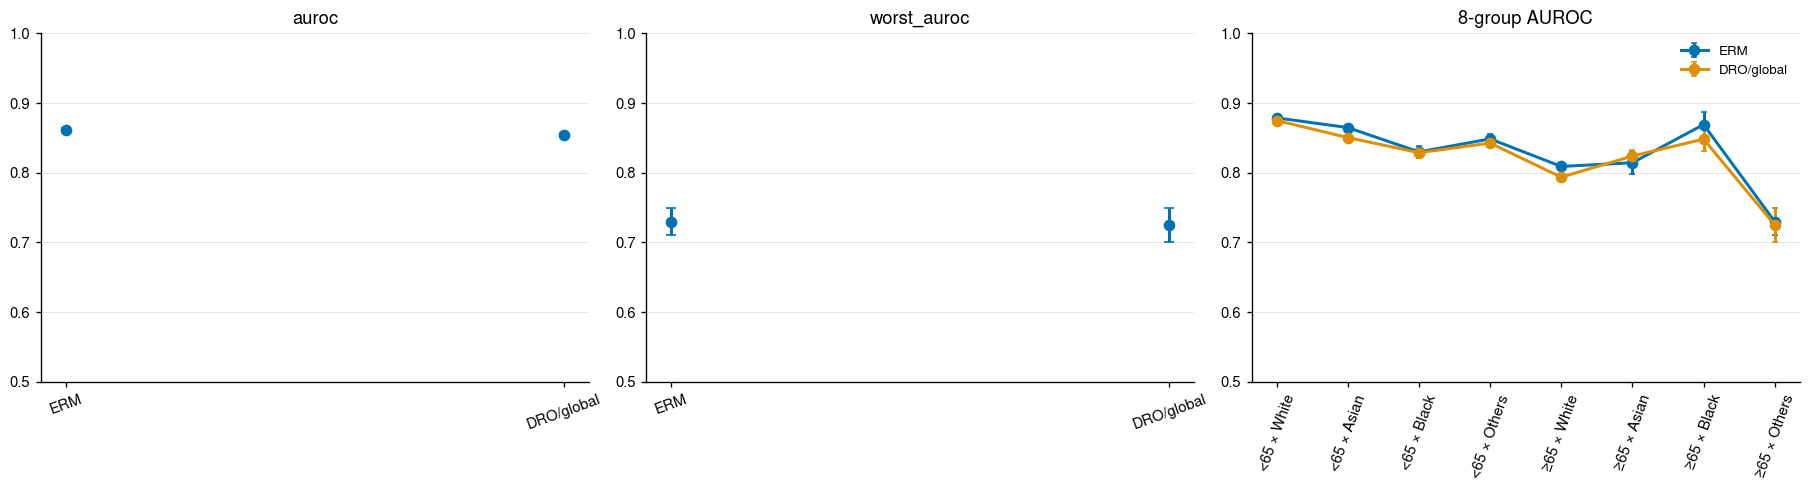

In [5]:
counts = subgroup[subgroup.condition == next(iter(CONDITIONS))].query("seed == 42")[
    ["group_id", "group", "n", "n_positive", "n_negative"]
]
counts.to_csv(RESULTS / "group_counts.csv", index=False)
print(f"test全体: {len(frame)}, 8群対象: {(group_ids(frame) >= 0).sum()}, 属性欠損除外: {(group_ids(frame) < 0).sum()}")
display(counts.set_index("group"))
group_stats = subgroup.groupby(["group", "condition"], sort=False)[["auroc", "bacc"]].agg(["mean", "std"])
group_stats.to_csv(RESULTS / "subgroup_mean_std.csv")
display(group_stats.round(4))
fig = plot_performance(summary, subgroup, LABELS)
fig.savefig(FIGURES / "performance.png", dpi=160)
plt.show()

## qのepoch推移

実線はepoch末q、破線はbest checkpoint epoch（0始まり）。q_mean・群内weighted CE・countもCSVへ保存する。qが大きい群とtestで悪い群が一致するとは限らない。

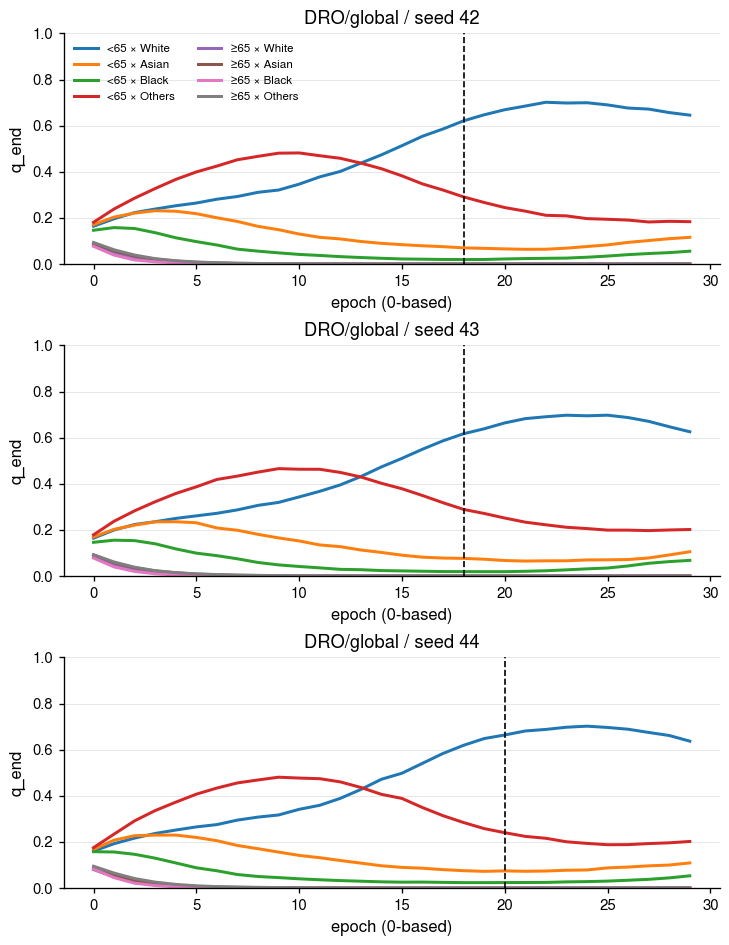

,condition,seed,max_q_group,max_train_loss_group,worst_test_auroc_group
0,M02,42,<65 × White,<65 × White,≥65 × Others
1,M02,43,<65 × White,<65 × White,≥65 × Others
2,M02,44,<65 × White,<65 × Black,≥65 × Others


In [6]:
q_history = read_q_history(directories, provenance)
q_history.to_csv(RESULTS / "q_history.csv", index=False)
fig = plot_q(q_history, LABELS)
fig.savefig(FIGURES / "q_end_epochs.png", dpi=160)
plt.show()
q_best = q_history[q_history.epoch == q_history.best_epoch].copy()
q_best.to_csv(RESULTS / "q_at_best.csv", index=False)
q_max = q_best.loc[q_best.groupby(["condition", "seed"]).q_end.idxmax(), ["condition", "seed", "group"]].rename(
    columns={"group": "max_q_group"}
)
loss_max = q_best.loc[q_best.groupby(["condition", "seed"]).loss.idxmax(), ["condition", "seed", "group"]].rename(
    columns={"group": "max_train_loss_group"}
)
dro_groups = subgroup[subgroup.condition.isin(q_best.condition.unique())]
test_worst = dro_groups.loc[
    dro_groups.groupby(["condition", "seed"]).auroc.idxmin(), ["condition", "seed", "group"]
].rename(columns={"group": "worst_test_auroc_group"})
q_diagnostics = q_max.merge(loss_max, on=["condition", "seed"]).merge(test_worst, on=["condition", "seed"])
q_diagnostics.to_csv(RESULTS / "q_diagnostics.csv", index=False)
display(q_diagnostics)

## TODO

- 他モデルでの再現確認：M03→M04、M07→M08、M16→M17。
- 単独属性・患者単位の不確実性とq／群lossの詳細な対応を確認。3seedで方式の優劣を断定しない。